<center><h1>Sarepaka_Abhishek_HW3</h1></center>
<br>
<br>

Name: Abhishek Sarepaka
<br>
Github Username: asarepaka
<br>
USC ID: 9325583863

## 1. Time Series Classification Part 1: Feature Creation/Extraction

### (a) Download Data

Package imports

In [5]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)

Get the AReM Data Set

In [3]:
path = '/Users/abhisheksarepaka/Downloads/Homework 3, 4 Data/AReM'

folders = ["bending1", "bending2", "cycling", "lying", "sitting", "standing", "walking"]
ts = ["avg_rss12", "var_rss12", "avg_rss13", "var_rss13", "avg_rss23", "var_rss23"]


data = []
for folder in folders:
    files = [f for f in os.listdir(os.path.join(path, folder)) if f.endswith('.csv')]
    for i in range(1, len(files) + 1):
        df = pd.read_csv(os.path.join(path, folder, f'dataset{i}.csv'), skiprows=5, header=None,
                         names=['time'] + ts, usecols=range(7), sep=r'[,\s]+', engine='python')
        data.append({'activity': folder, 'dataset': i, 'data': df})
    
#check data
print("Activities:", sorted(set(row["activity"] for row in data)))
print('number of instances:', len(data))
df = data[0]['data']
df.head()

Activities: ['bending1', 'bending2', 'cycling', 'lying', 'sitting', 'standing', 'walking']
number of instances: 88


,time,avg_rss12,var_rss12,avg_rss13,var_rss13,avg_rss23,var_rss23
0,0,39.25,0.43,22.75,0.43,33.75,1.3
1,250,39.25,0.43,23.00,0.00,33.00,0.0
2,500,39.25,0.43,23.25,0.43,33.00,0.0
3,750,39.50,0.50,23.00,0.71,33.00,0.0
4,1000,39.50,0.50,24.00,0.00,33.00,0.0


### (b) Test and Train Data

In [4]:
train = []
test = []

for i in data:
    activity = i['activity']
    number = i['dataset']

    if activity == 'bending1' or activity == 'bending2':
        if number <= 2:
            test.append(i)
        else:
            train.append(i)
    else:
        if number <= 3:
            test.append(i)
        else:
            train.append(i)

print("Train:", len(train))
print("Test:", len(test))

print("\nTraining instances by folder:")
print(pd.Series([r["activity"] for r in train]).value_counts().sort_index())
print("\nTest instances by folder:")
print(pd.Series([r["activity"] for r in test]).value_counts().sort_index())

Train: 69
Test: 19

Training instances by folder:
bending1     5
bending2     4
cycling     12
lying       12
sitting     12
standing    12
walking     12
Name: count, dtype: int64

Test instances by folder:
bending1    2
bending2    2
cycling     3
lying       3
sitting     3
standing    3
walking     3
Name: count, dtype: int64


### (c) Feature Extraction

#### i. Research

1. Min and max: The lowest and highest values in the series
2. Mean & median: Measures of central tendency
3. Quartiles: percentile split of data (Q1 - 25th percentile, Q2 - 50th, Q3 - 75th)
4. Range & IQR: The total spread of values (max - min) and the spread of the middle 50% (Q3 - Q1)
5. Standard deviation and variance (how spread out the values are)
6. Skewness: Is the data symmetric or asymmetric?
7. Kurtosis: How heavy are the tails and how many extreme values?
8. Root mean square (RMS) & energy: The overall size of the signal (square root of the mean of squared values) and the sum of squared values
9. Autocorrelation: How similar the signal is to a shifted copy of itself (shows repeating patterns)
10. Entropy: How random or predictable the signal is
11. Stationarity (ADF test): A series is stationary if its mean and variance stay the same over time. The ADF test checks if a small p-value (< 0.05) means the series is stationary 
12. Seasonality: Whether the signal has a repeating pattern at a fixed period  

#### ii. Extraction

In [15]:
rows = []

for i in data:
    df = i["data"]
    row = {}

    for n, col_name in enumerate(ts, start=1):
        col = df[col_name]
        num = str(n)

        row["min" + num] = col.min()
        row["max" + num] = col.max()
        row["mean" + num] = col.mean()
        row["median" + num] = col.median()
        row["std" + num] = col.std()
        row["1st_quart" + num] = col.quantile(0.25)
        row["3rd_quart" + num] = col.quantile(0.75)

    row["activity"] = i["activity"]
    rows.append(row)

features = pd.DataFrame(rows)
features.index = range(1, len(features) + 1)
features.index.name = "Instance"
features




,min1,max1,mean1,median1,std1,1st_quart1,3rd_quart1,min2,max2,mean2,median2,std2,1st_quart2,3rd_quart2,min3,max3,mean3,median3,std3,1st_quart3,3rd_quart3,min4,max4,mean4,median4,std4,1st_quart4,3rd_quart4,min5,max5,mean5,median5,std5,1st_quart5,3rd_quart5,min6,max6,mean6,median6,std6,1st_quart6,3rd_quart6,activity
Instance,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
1,37.25,45.00,40.624792,40.50,1.476967,39.25,42.0000,0.0,1.30,0.358604,0.430,0.322605,0.00,0.5000,4.00,29.50,19.040937,19.250,4.462952,16.00,23.2500,0.0,7.23,0.832542,0.50,0.965659,0.0000,1.1200,27.25,38.25,34.311292,35.00,2.188449,33.0000,36.00,0.00,1.92,0.570583,0.43,0.582915,0.0000,1.3000,bending1
2,38.00,45.67,42.812812,42.50,1.435550,42.00,43.6700,0.0,1.22,0.372437,0.470,0.289158,0.00,0.5000,2.00,29.50,20.096979,21.000,3.893737,19.00,22.2500,0.0,5.76,0.876438,0.50,1.047259,0.0000,1.1450,27.67,38.50,33.024583,33.00,1.995255,32.0000,34.50,0.00,3.11,0.571083,0.43,0.601010,0.0000,1.3000,bending1
3,35.00,47.40,43.954500,44.33,1.558835,43.00,45.0000,0.0,1.70,0.426250,0.470,0.338690,0.00,0.5000,6.50,29.75,22.122354,23.000,3.030943,19.75,24.0000,0.0,4.44,0.497312,0.43,0.550657,0.0000,0.8300,29.00,38.50,35.588458,36.00,1.999604,35.3625,36.50,0.00,1.79,0.493292,0.43,0.513506,0.0000,0.9400,bending1
4,33.00,47.75,42.179812,43.50,3.670666,39.15,45.0000,0.0,3.00,0.696042,0.500,0.630860,0.00,1.1200,8.50,30.00,22.183625,23.000,3.810469,20.50,24.3725,0.0,5.15,0.989917,0.83,0.953730,0.4300,1.3000,20.00,38.67,33.493917,35.00,3.849448,30.4575,36.33,0.00,2.18,0.613521,0.50,0.524317,0.0000,1.0000,bending1
5,33.00,45.75,41.678063,41.75,2.243490,41.33,42.7500,0.0,2.83,0.535979,0.500,0.405469,0.43,0.7100,3.00,28.25,19.006563,19.125,4.087107,16.50,22.0625,0.0,6.42,0.841875,0.50,0.928801,0.4300,1.1200,23.67,37.50,29.857083,30.00,2.411026,28.4575,31.25,0.00,1.79,0.383292,0.43,0.389164,0.0000,0.5000,bending1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
84,19.50,45.33,33.586875,34.25,4.650935,30.25,37.0000,0.0,14.67,4.576562,4.260,2.461077,2.87,6.1050,7.33,23.25,15.317854,15.330,2.970440,13.25,17.2700,0.0,9.00,3.227229,3.10,1.647474,2.0500,4.2600,6.33,25.00,15.892146,16.00,3.283983,13.7300,18.25,0.00,8.32,3.259729,3.11,1.640243,2.0500,4.3225,walking
85,19.75,45.50,34.322750,35.25,4.752477,31.00,38.0000,0.0,13.47,4.456333,3.900,2.599284,2.49,5.9700,6.25,22.25,15.209771,15.250,2.711022,13.50,17.0000,0.0,9.00,3.277229,3.11,1.500046,2.1700,4.3900,6.25,23.25,15.550458,15.75,3.119856,13.5000,17.75,0.00,9.67,3.432563,3.20,1.732727,2.1575,4.5650,walking
86,19.50,46.00,34.546229,35.25,4.842294,31.25,37.8125,0.0,12.47,4.371958,4.135,2.360448,2.49,5.8000,7.00,22.67,15.185729,15.250,2.757604,13.25,17.0000,0.0,8.34,3.028687,2.86,1.665184,1.7900,4.1100,7.00,22.75,15.759542,15.75,2.823124,14.0000,17.75,0.00,10.00,3.338125,3.08,1.656742,2.1600,4.3350,walking


#### iii. Standard Deviation

In [19]:
cols = list(features.columns)
cols.remove("activity")
features[cols].std()

rows = []

for col in cols:
    x = features[col].values
    stds = []

    for n in range(1000):
        sample = np.random.choice(x, size=len(x), replace=True)
        stds.append(sample.std(ddof=1))

    low = np.percentile(stds, 5)
    high = np.percentile(stds, 95)
    rows.append([col, x.std(ddof=1), low, high])

confi_inter = pd.DataFrame(rows, columns=["feature", "std", "90% CI lower", "90% CI upper"])
confi_inter

,feature,std,90% CI lower,90% CI upper
0,min1,9.569975,8.270497,10.704707
1,max1,4.394362,3.365392,5.277428
2,mean1,5.335718,4.710741,5.875059
3,median1,5.440054,4.763890,5.958733
4,std1,1.772153,1.573991,1.946358
5,1st_quart1,6.153590,5.550447,6.621083
6,3rd_quart1,5.138925,4.277549,5.893755
7,min2,0.000000,0.000000,0.000000
8,max2,5.062729,4.648117,5.393226
9,mean2,1.574164,1.395024,1.700269


#### iv. Select Features

Based on my judgement, the three most important time-domain features would be based on where the boxes for the different activities are at different heights, as each feature can then tell the activities apart. To best interpret this, we can go ahead and visualize our variables using box plots. 

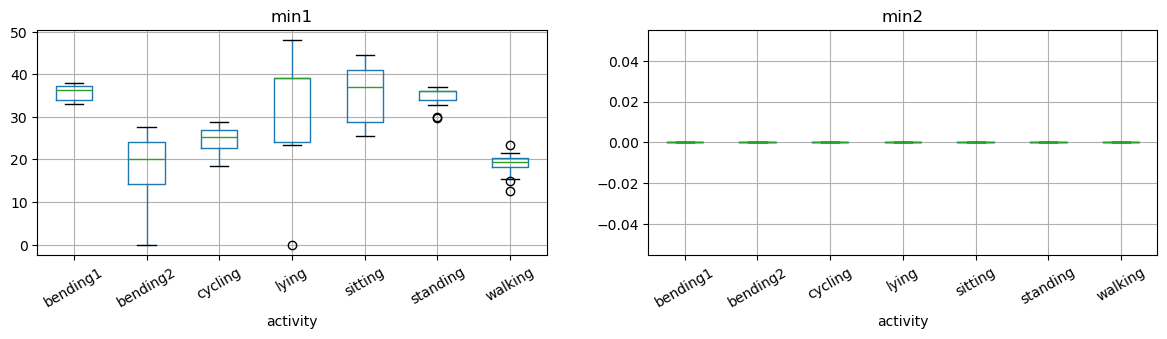

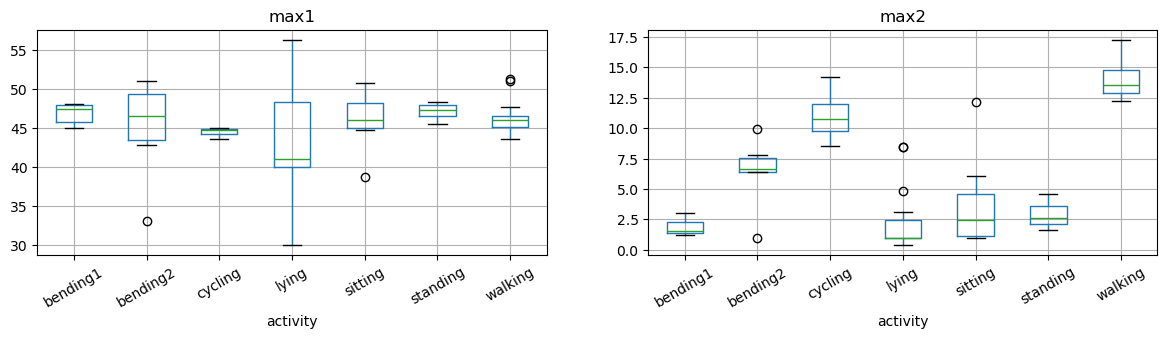

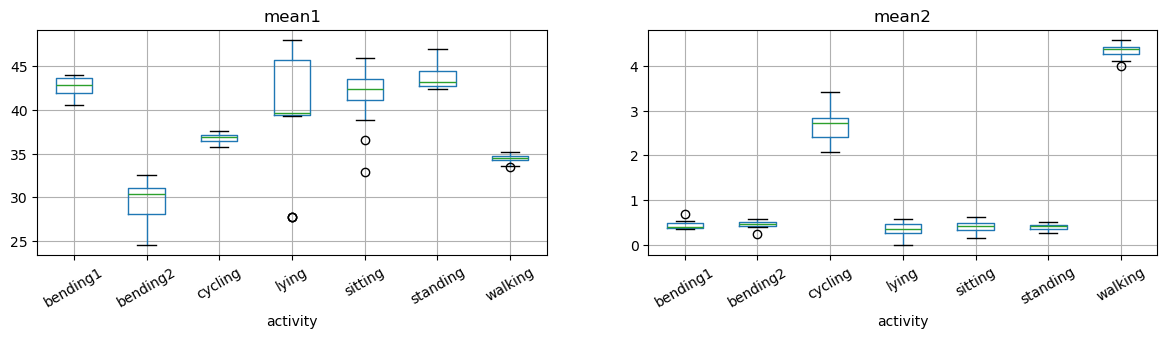

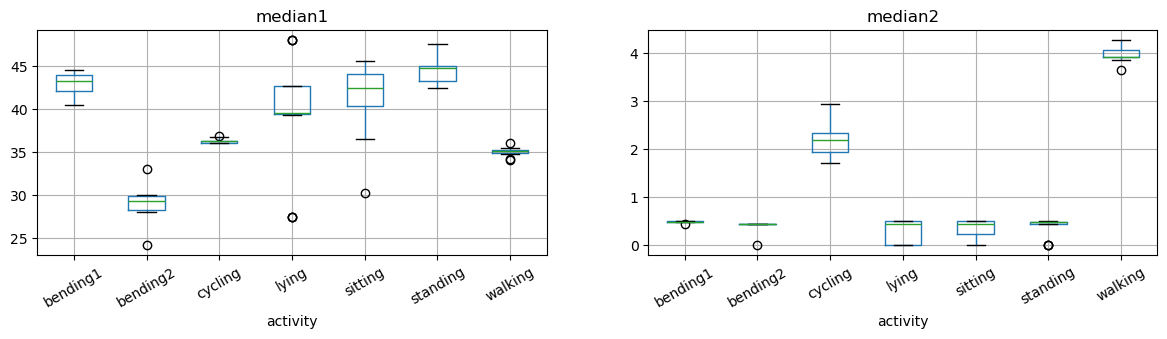

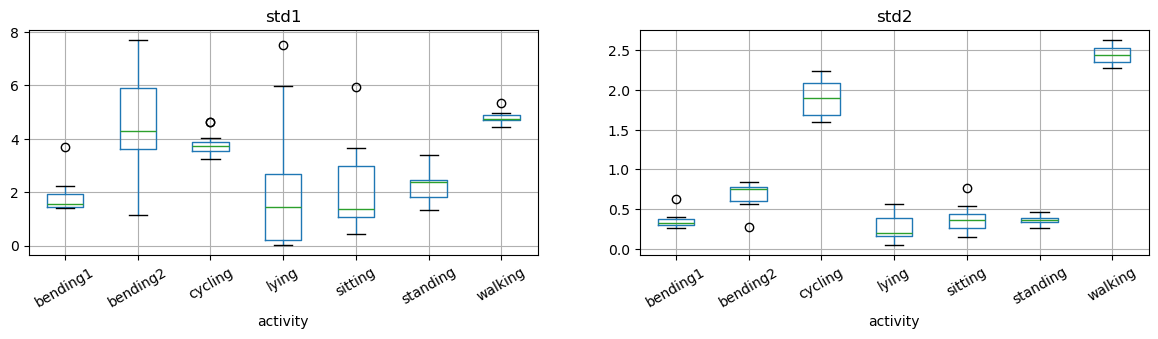

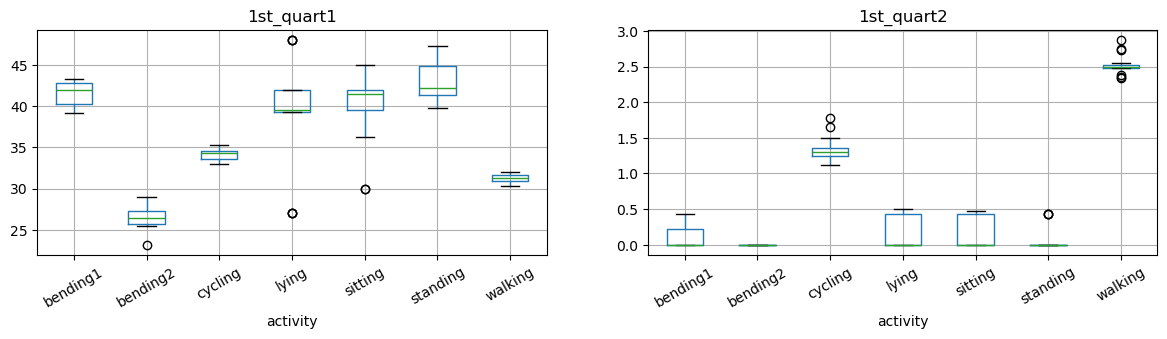

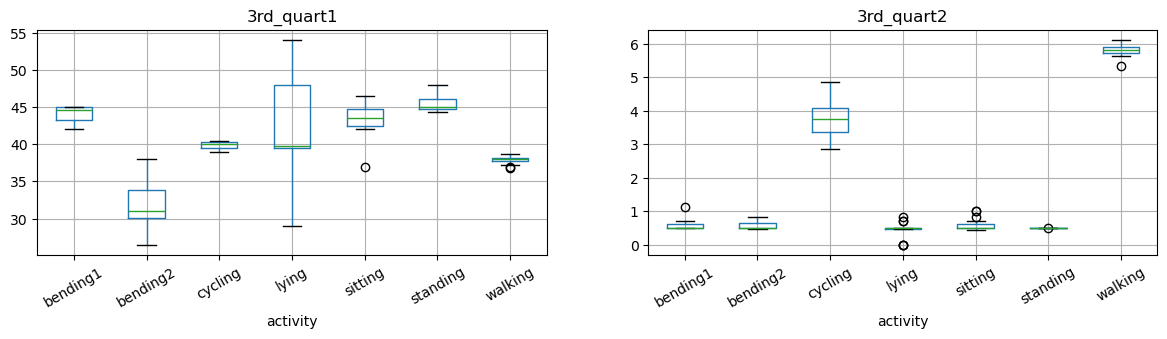

In [22]:
stats = ["min", "max", "mean", "median", "std", "1st_quart", "3rd_quart"]

for stat in stats:
    fig, axes = plt.subplots(1, 2, figsize=(14, 3))

    features.boxplot(column=stat + "1", by="activity", ax=axes[0], rot=30)
    axes[0].set_title(stat + "1")

    features.boxplot(column=stat + "2", by="activity", ax=axes[1], rot=30)
    axes[1].set_title(stat + "2")

    plt.suptitle("")
    plt.show()

As can be seen in the box plots, the mean, median, and 3rd quartile do the best job of separating the activities, as:

1. The Mean in time series 1 shows the boxes sit at clearly different heights. Bending2 and walking are much lower than standing and bending1, so the mean can tell these activities apart.
2. The Median follows almost the same pattern as the mean, but it is less affected by sudden spikes in the signal, which makes it more reliable.
3. The 3rd quartile range for time series 2 shows that walking and cycling a much higher than activities with little movement, such as  lying and sitting. This shows how much the person is moving.

Therefore, I chose mean, median, and 3rd quartile as my three most important features.

## 2. ISLR 3.7.4

 I collect a set of data (n = 100 observations) containing a single
predictor and a quantitative response. I then fit a linear regression
model to the data, as well as a separate cubic regression, i.e. Y =
β0 + β1X + β2X2 + β3X3 + ϵ.

### (a) Linear Train
(a) Suppose that the true relationship between X and Y is linear,
i.e. Y = β0 + β1X + ϵ. Consider the training residual sum of
squares (RSS) for the linear regression, and also the training
RSS for the cubic regression. Would we expect one to be lower
than the other, would we expect them to be the same, or is there
not enough information to tell? Justify your answer.

The cubic model should have a lower training RSS because it includes the linear model plus two extra terms, X^2 and X^3. These terms allow it to fit the data better by following small variations and noise. However, this can lead to overfitting, so it may not perform better on new data.

### (b) Linear Test
(b) Answer (a) using test rather than training RSS.

I would expect the linear regression to have a lower test RSS because the true relationship is linear. The cubic model’s extra X^2 and X^3 terms may cause it to fit random noise in the training data, making its predictions less accurate on new data.

### (c) Not Linear Train

(c) Suppose that the true relationship between X and Y is not linear,
but we don’t know how far it is from linear. Consider the training
RSS for the linear regression, and also the training RSS for the
cubic regression. Would we expect one to be lower than the
other, would we expect them to be the same, or is there not
enough information to tell? Justify your answer.

I would expect the cubic regression to have a lower training RSS because it includes the linear model plus extra X^2 and X^3 terms. This allows it to fit the data at least as well as the linear model. Since the true relationship is not linear, the extra terms can help the cubic model fit the data better, resulting in a lower or equal training RSS.

### (d) Not Linear Testing
(d) Answer (c) using test rather than training RSS.


To see which model would have the lower test RSS, we would need to see the tradeoff between bias and variance, and since that information isnt provided, it is hard to understand which can be bigger. If the true relationship is far from linear, the cubic model will likely have a lower test RSS because it can fit the curve better. If the relationship is almost linear, the linear model might perform better because the cubic model could overfit the noise.


## 3. ISLR 3.7.3 - Extra Practice 

## 3. ISLR 3.7.5 - Extra Practice 